In [1]:
import os

fun_list = ['SVWN', 'BLYP', 'PBE', 'TPSS', 'B3LYP', 'PBE0']
for fun in fun_list:
    try:
        os.mkdir(fun)
        print(f"Created directory: {fun}")
    except FileExistsError:
        print(f"Directory already exists: {fun}")

Directory already exists: SVWN
Directory already exists: BLYP
Directory already exists: PBE
Directory already exists: TPSS
Directory already exists: B3LYP
Directory already exists: PBE0


In [2]:
for fun in fun_list:
    filename = f"{fun}/GL.py"
    with open('GL.py', 'r') as file:
        lines = file.readlines()
        lines[9] = f"fun = '{fun}'\n"
        with open(filename, 'w') as new_file:
            new_file.writelines(lines)

In [3]:
import shutil

for fun in fun_list:
    shutil.copy('wt_sub_py.sh', f"{fun}/wt_sub_py.sh")

In [1]:
import numpy as np

fun_list = ['SVWN', 'BLYP', 'PBE', 'TPSS', 'B3LYP', 'PBE0']
Ediff = {}
Gdiff = {}

for fun in fun_list:
    Exe = np.load(f'{fun}/Energy.npy')
    ref = Exe[-1]
    Exe = Exe[:-1]
    mae  = np.mean(np.abs(Exe-ref), axis=1)
    Ediff[fun] = mae
    Grad = np.load(f'{fun}/Gradient.npy')
    ref = Grad[-1]
    Grad = Grad[:-1]
    mae  = np.mean(np.abs(Grad-ref), axis=(1,2,3))
    Gdiff[fun] = mae

In [2]:
Ediff

{'SVWN': array([1.18105905e-04, 1.08046844e-06, 5.11482012e-08, 3.55937003e-09,
        2.97134397e-10, 2.79162639e-11, 2.84457724e-12, 3.00594792e-13,
        2.99448209e-14, 3.42726307e-15, 4.06309765e-15, 3.95658884e-15,
        5.08439794e-15, 1.19942404e-15, 7.43987566e-15, 8.86156719e-15,
        3.93749118e-15, 1.28480547e-14, 6.91263731e-15, 6.94698310e-15,
        9.65812633e-15, 5.74662364e-15, 1.24309085e-14, 6.52119792e-15,
        7.90574003e-15, 5.83601406e-15, 7.21629354e-15, 1.04981771e-14]),
 'BLYP': array([6.90873554e-05, 7.38494499e-06, 1.85639019e-07, 1.02204269e-08,
        1.02551279e-09, 1.28128727e-10, 1.70253119e-11, 2.31370822e-12,
        3.16684672e-13, 4.39862267e-14, 9.55511411e-15, 7.48423036e-15,
        5.53585061e-15, 8.34185916e-15, 4.12728510e-15, 8.33763980e-15,
        3.73555627e-15, 8.67492085e-15, 8.92620013e-15, 5.22383082e-15,
        6.01124130e-15, 7.94996711e-15, 1.23330770e-14, 6.57967526e-15,
        1.95872844e-15, 5.59390498e-15, 2.9565

In [3]:
Gdiff

{'SVWN': array([4.43365065e-05, 1.07822787e-07, 2.98989922e-08, 3.71059797e-09,
        4.09422248e-10, 4.65070732e-11, 5.51009998e-12, 6.78779696e-13,
        8.63802502e-14, 1.63708745e-14, 4.71950411e-15, 4.70519281e-15,
        5.07841252e-15, 4.11822875e-15, 4.53105033e-15, 3.84342624e-15,
        3.46361152e-15, 3.70374247e-15, 4.70841742e-15, 4.37416287e-15,
        3.29274660e-15, 3.69153279e-15, 4.54600764e-15, 3.84409089e-15,
        4.26263856e-15, 3.89162754e-15, 4.07938993e-15, 5.07680858e-15]),
 'BLYP': array([6.19622906e-05, 3.42867690e-06, 5.15832538e-08, 1.05166049e-08,
        1.46201849e-09, 2.12503227e-10, 3.21305568e-11, 4.90516529e-12,
        7.45894387e-13, 1.14277177e-13, 4.05625285e-15, 4.42786179e-15,
        5.17800145e-15, 4.75873192e-15, 4.09621198e-15, 4.64900375e-15,
        4.72795017e-15, 4.73218056e-15, 3.95037841e-15, 5.53333645e-15,
        3.54906706e-15, 4.31024870e-15, 4.45703547e-15, 3.68713450e-15,
        4.86322693e-15, 5.15695411e-15, 4.3268

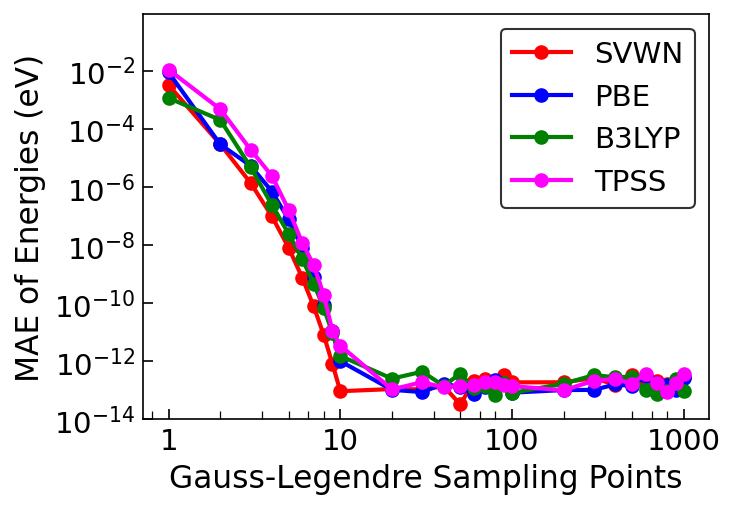

In [39]:
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, ScalarFormatter

fun_list = ['SVWN', 'PBE', 'B3LYP', 'TPSS']
colors = ['#FF0000', '#0000FF', '#008000', '#FF00FF', '#00FFFF', '#FFA500']
x = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100,
            200, 300, 400, 500, 600, 700, 800, 900, 1000])

fig, ax = plt.subplots(figsize=(5, 3.5), dpi=150)
for fun in fun_list:
    ax.plot(x, Ediff[fun]*27.2114, marker='o', label=fun, linestyle='-', linewidth=2, color=colors[fun_list.index(fun)])
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(1e-14, 9e-1)
ax.set_xlabel("Gauss-Legendre Sampling Points", fontsize=15)
ax.set_ylabel("MAE of Energies (eV)", fontsize=15)
ax.tick_params(direction='in', length=5)
ax.xaxis.set_minor_locator(LogLocator(base=10.0, subs=np.linspace(0.2, 0.8, 5), numticks=10))
ax.xaxis.set_major_formatter(ScalarFormatter())
ax.xaxis.get_major_formatter().set_scientific(False)
ax.legend(fontsize=14, loc='upper right', frameon=True, edgecolor='black')
ax.tick_params(axis='x', which='minor', direction='in', length=4)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.tight_layout()
# plt.show()
plt.savefig('EnergyGL.png', dpi=600, bbox_inches='tight', pad_inches=0.1)

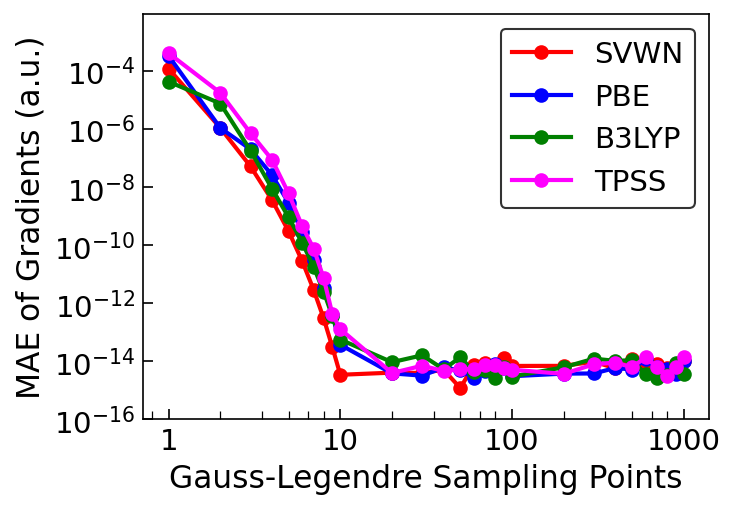

In [38]:
fun_list = ['SVWN', 'PBE', 'B3LYP', 'TPSS']
colors = ['#FF0000', '#0000FF', '#008000', '#FF00FF', '#00FFFF', '#FFA500']


fig, ax = plt.subplots(figsize=(5, 3.5), dpi=150)
for fun in fun_list:
    ax.plot(x, Ediff[fun], marker='o', label=fun, linestyle='-', linewidth=2, color=colors[fun_list.index(fun)])
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(1e-16, 9e-3)
ax.set_xlabel("Gauss-Legendre Sampling Points", fontsize=15)
ax.set_ylabel("MAE of Gradients (a.u.)", fontsize=15)
ax.tick_params(direction='in', length=5)
ax.xaxis.set_minor_locator(LogLocator(base=10.0, subs=np.linspace(0.2, 0.8, 5), numticks=10))
ax.legend(fontsize=14, loc='upper right', frameon=True, edgecolor='black')
ax.tick_params(axis='x', which='minor', direction='in', length=4)
ax.xaxis.set_major_formatter(ScalarFormatter())
ax.xaxis.get_major_formatter().set_scientific(False)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.tight_layout()
# plt.show()
plt.savefig('GradientGL.png', dpi=600, bbox_inches='tight', pad_inches=0.1)